[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/notebooks/lecture6_notebook.ipynb)

# Blockchain Applications — Lecture 6: Stablecoins II: De-pegging Pressure Index and Portfolios

*Lecture notebook. Daniel Traian Pele, Bucharest University of Economic Studies.*

Lecture 5 watched one pool. Can we measure pressure on the *whole* stablecoin system in one number, and is that number useful?
This notebook reproduces the estimates, tables and charts of Lecture 6:

1. comparing tokens with different anchors: reference-adjusted deviations, the effect of the adjustment, and peg quality;
2. quantile regression (and why a rolling 5% quantile counts ranks, not depth) and the least absolute shrinkage and selection operator (Lasso);
3. the De-pegging Pressure Index (DPI): construction, the index on one day, which coins carry it, regimes and event responses, event windows day by day;
4. inside the tail links: who is linked to whom, how sparse the models become under pressure, and the DPI against simple stress gauges;
5. further material: a data check, a Shapley decomposition of the information blocks, and four long-only portfolio rules.

Main source: Fan, Sha, Härdle & Pele (2026), *Reference-adjusted Quantile Lasso reveals regime-dependent stablecoin depegging pressure*, working paper, based on Fan (2026), MSc thesis, HU Berlin.
The idea of using a selected penalty as a risk measure comes from the Financial Risk Meter (FRM) of [Mihoci, Althof, Chen & Härdle (2020)](https://doi.org/10.1108/S0731-905320200000042016).
Results of the working paper are typed in from it (printed as "working paper: ..." next to our estimates); every other number is estimated here from EODHD data.

Data: daily closes from EOD Historical Data (EODHD) for 10 stablecoins, the euro and gold, and four market variables, 1 January 2020 – 23 October 2026.
One basis point (bp) is 0.01%.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your Google Drive) and work in that copy.
> Files you create while the notebook runs (CSV files, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/Blockchain_Applications/Lecture_6'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))

## Setup: packages, chart style and data

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## Data

Ten stablecoins: Tether (USDT), USD Coin (USDC), Dai (DAI), TrueUSD (TUSD), Pax Dollar (USDP), Gemini Dollar (GUSD), Binance USD (BUSD), Synthetix USD (sUSD), Pax Gold (PAXG, one troy ounce of gold) and STASIS Euro (EURS).
The paper also uses the Rupiah Token (IDRT), which has no EODHD data after September 2023.
Market variables: the US dollar index (DXY), the CBOE volatility index (VIX), the Standard & Poor's 500 index (S&P 500) and the 1-year US Treasury yield.

Prices are put on a calendar of all days; a missing close is filled from the past for at most 7 days.
Gold (XAU/USD) and EUR/USD, the references of PAXG and EURS, use Monday–Friday closes with repeated closes removed (the weekend bars in the files come from a thin weekend session); the Friday close is carried over Saturday and Sunday, while the tokens trade every day.

**Data check** (as in Lecture 1): a daily move beyond 1,000 bp that reverses by at least 90% the next day is treated as a recording error. The rule needs the *next* day's price, so it is a retrospective cleaning: the descriptive statistics use the cleaned prices, while every estimate made "on day $t$" (the DPI, the portfolio weights) sees the last day before $t$ as recorded, because that print cannot yet be checked. The flagged prints are listed in the further material at the end.

In [4]:
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from scipy.optimize import linprog, minimize
from joblib import Parallel, delayed
import matplotlib
import matplotlib.dates

END = '2026-10-23'                           # last day of the lecture sample
END_PAPER = '2026-05-31'                     # last day of the paper's sample
COINS = ['USDT', 'USDC', 'DAI', 'TUSD', 'USDP', 'GUSD', 'BUSD', 'SUSD', 'PAXG', 'EURS']
cal = pd.date_range('2020-01-01', END)


def finish_fig(fig, name, ncol=3, bottom=0.12):
    """Legend below the plot, room for it, then save and show."""
    legend_below(fig, ncol=ncol)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)


def weekdays(x):
    """Monday-Friday closes, repeated closes removed."""
    x = x[x.index.dayofweek < 5]
    return x[x.diff() != 0]


ref = {'EURS': weekdays(daily('EURUSD.FOREX', END)), 'PAXG': weekdays(daily('XAUUSD.FOREX', END))}
P = pd.DataFrame({c: daily(f'{c}-USD.CC', END) for c in COINS}).reindex(cal).ffill(limit=7)    # past-only fill, at most 7 days
lr = 1e4 * np.log(P).diff()
bad = (lr.abs() > 1000) & (-lr.shift(-1) / lr >= 0.9)                                        # bad prints
FLAGS = pd.DataFrame([(c, t_.date(), P.loc[t_, c], lr.loc[t_, c]) for t_, c in bad.stack()[bad.stack()].index],
                     columns=['coin', 'date', 'close (USD)', 'log return (bp)'])
P_raw = P.copy()                                                                             # prices as recorded
P = P.mask(bad).ffill(limit=7)                                                               # retrospective cleaning
Bm = pd.DataFrame({c: (ref[c].reindex(cal).ffill() if c in ref else pd.Series(1.0, index=cal)) for c in COINS})
mac = pd.DataFrame({'DXY': daily('DXY.INDX', END), 'VIX': daily('VIX.INDX', END), 'SPX': daily('GSPC.INDX', END),
                    'US1Y': daily('US1Y.GBOND', END)}).reindex(cal).ffill()
M = pd.DataFrame({'DXY': np.log(mac['DXY']).diff(), 'VIX': np.log(mac['VIX']).diff(), 'SPX': np.log(mac['SPX']).diff(),
                  'US1Y': mac['US1Y'].diff()}).shift(1)                                       # changes, lagged one day
print(f'calendar {cal[0].date()} to {cal[-1].date()} ({len(cal)} days); bad prints removed: {len(FLAGS)}')

calendar 2020-01-01 to 2026-10-23 (2488 days); bad prints removed: 9


## 1. Comparing different anchors

### Reference adjustment

Not every stablecoin targets the dollar: EURS tracks the euro (EUR) and PAXG one ounce of gold (XAU).
Let $P_{i,t}$ be the dollar price of token $i$ and $B_{i,t}$ the dollar value of its reference asset. The reference-adjusted deviation and return, in bp, are

$$ d_{i,t} = 10^4\left(\frac{P_{i,t}}{B_{i,t}} - 1\right), \qquad r_{i,t} = 10^4\,\Delta \ln\frac{P_{i,t}}{B_{i,t}}, $$

with $B = 1$ for dollar tokens, EUR/USD for EURS and XAU/USD for PAXG. Without the adjustment, a 1% move of the euro would look like a 100 bp "depeg" of EURS.
Worked example: EURS at 1.1194 USD while EUR/USD = 1.1202.

In [5]:
print(f'EURS reference-adjusted deviation: 10^4 (1.1194 / 1.1202 - 1) = {1e4 * (1.1194 / 1.1202 - 1):.1f} bp')
D = 1e4 * (P / Bm - 1)                       # reference-adjusted signed deviation, bp
R = 1e4 * np.log(P / Bm).diff()              # reference-adjusted log return, bp
D_raw = 1e4 * (P_raw / Bm - 1)               # deviations as recorded (no cleaning)
WIN_SD = 90                                  # window of the rolling standard deviations below

EURS reference-adjusted deviation: 10^4 (1.1194 / 1.1202 - 1) = -7.1 bp


### Effect of the reference adjustment

The 90-day standard deviation of three daily returns, in bp: the token's dollar return $\Delta \ln P_{i,t}$, the reference's dollar return $\Delta \ln B_{i,t}$ and the reference-adjusted return $r_{i,t}$ (prices as recorded, January 2021 – May 2026).
If the token tracks its reference, the adjusted return is much calmer than the dollar return.

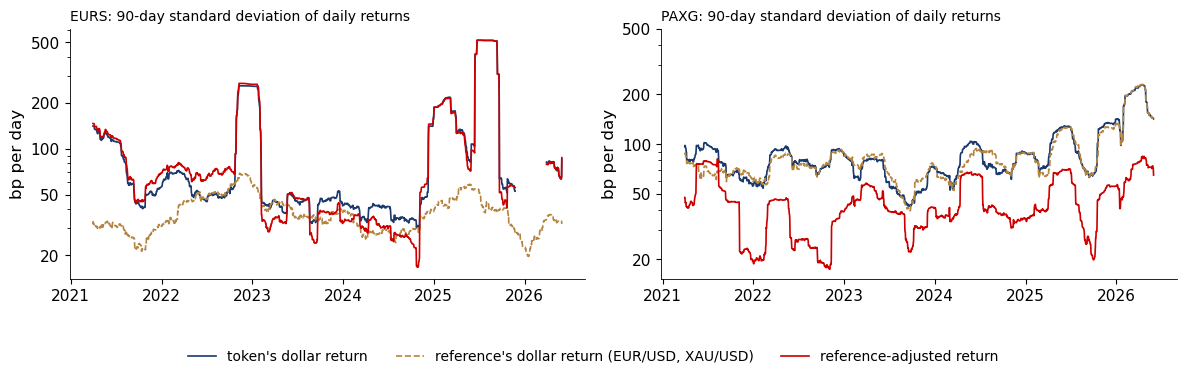

largest EUR/USD move: 2025-04-10, +227 bp; EURS in USD +159 bp, against the euro -68 bp


,"sd, token in USD (bp)","sd, reference in USD (bp)","sd, adjusted (bp)",correlation token-reference
EURS,145.76,39.25,146.98,0.10
PAXG,95.85,93.58,47.53,0.87


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
rows_ = {}
for j_, c in enumerate(['EURS', 'PAXG']):
    r_u = 1e4 * np.log(P_raw[c]).diff().loc['2021-01-01':END_PAPER]                 # token in USD
    r_b = 1e4 * np.log(Bm[c]).diff().loc['2021-01-01':END_PAPER]                    # reference in USD
    r_a = 1e4 * np.log(P_raw[c] / Bm[c]).diff().loc['2021-01-01':END_PAPER]         # reference-adjusted
    rows_[c] = {'sd, token in USD (bp)': r_u.std(), 'sd, reference in USD (bp)': r_b.std(), 'sd, adjusted (bp)': r_a.std(),
                'correlation token-reference': r_u.corr(r_b)}
    for x_, col, ls, lab in [(r_u, BLUE, '-', "token's dollar return"), (r_b, GOLD, '--', "reference's dollar return (EUR/USD, XAU/USD)"),
                             (r_a, RED, '-', 'reference-adjusted return')]:
        ax[j_].plot(x_.index, x_.rolling(WIN_SD).std(), color=col, ls=ls, lw=1.2, label=(lab if j_ == 0 else None))
    ax[j_].set_title(f'{c}: 90-day standard deviation of daily returns', fontsize=10, loc='left')
    ax[j_].set_ylabel('bp per day'); ax[j_].set_yscale('log'); ax[j_].set_yticks([20, 50, 100, 200, 500])
    ax[j_].yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g')); ax[j_].yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
finish_fig(fig, 'ba_l6_refadj', ncol=3, bottom=0.14)
r_e = 1e4 * np.log(Bm['EURS']).diff().loc['2021-01-01':END_PAPER]
big = r_e.abs().idxmax()
print(f'largest EUR/USD move: {big.date()}, {r_e.loc[big]:+.0f} bp; EURS in USD {1e4 * np.log(P_raw["EURS"]).diff().loc[big]:+.0f} bp, '
      f'against the euro {1e4 * np.log(P_raw["EURS"] / Bm["EURS"]).diff().loc[big]:+.0f} bp')
pd.DataFrame(rows_).T.round(2)

For PAXG the adjustment halves the noise: the token follows gold closely. For EURS the token's own noise, about four times that of the euro, dominates, and the adjustment cannot remove it.
The adjustment puts the target in the right unit; it does not remove noise that does not come from the reference.

### Peg quality, 2020 – May 2026

For each coin: the median absolute deviation $|d|$, the 5% quantile of $d$, and the share of days with $d \leq -100$ bp (a discount of at least 1%), over the paper's sample period.

In [7]:
Q = pd.DataFrame({c: {'median |d| (bp)': D[c].loc[:END_PAPER].dropna().abs().median(),
                      '5% quantile of d (bp)': D[c].loc[:END_PAPER].dropna().quantile(0.05),
                      '% days d <= -100 bp': 100 * (D[c].loc[:END_PAPER].dropna() <= -100).mean(),
                      'days': D[c].loc[:END_PAPER].notna().sum()} for c in COINS}).T
Q['working paper: median |d| (bp)'] = pd.Series({'USDC': 4.11, 'DAI': 7.06, 'USDT': 5.37, 'USDP': 7.63})
Q.sort_values('median |d| (bp)').round(2)

,median |d| (bp),5% quantile of d (bp),% days d <= -100 bp,days,working paper: median |d| (bp)
USDC,1.32,-5.00,0.17,2343.0,4.11
DAI,2.80,-8.98,0.68,2343.0,7.06
USDT,3.55,-11.25,0.09,2343.0,5.37
BUSD,3.67,-8.64,0.09,2343.0,NaN
USDP,7.29,-47.47,0.21,2343.0,7.63
TUSD,7.75,-37.78,2.09,2343.0,NaN
GUSD,17.70,-109.99,6.32,2343.0,NaN
PAXG,43.51,-124.41,9.13,2343.0,NaN
EURS,50.95,-251.88,17.11,2315.0,NaN
SUSD,56.32,-1883.38,25.99,2343.0,NaN


There are two tiers: the large dollar tokens stay within a few bp, while small, non-dollar or crypto-collateralised tokens are tens of bp off, with deep lower tails.
The data source matters for the levels (EODHD medians are lower than those of CoinGecko used in the paper), not for the ranking.

### Two tiers of peg quality

Distribution of $|d_{i,t}|$, January 2020 – May 2026, coins ordered by their median, log scale.

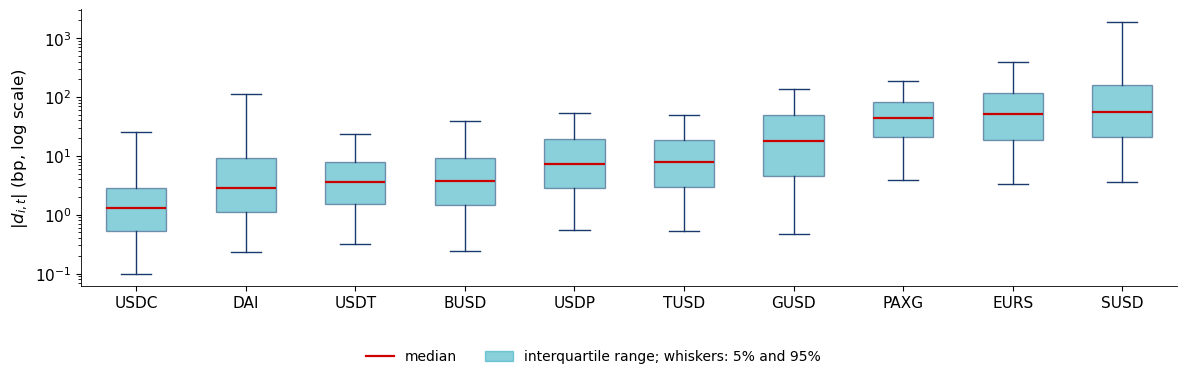

95% quantile of |d| (bp): {'USDC': 26.0, 'DAI': 114.0, 'USDT': 23.0, 'BUSD': 39.0, 'USDP': 54.0, 'TUSD': 49.0, 'GUSD': 139.0, 'PAXG': 186.0, 'EURS': 401.0, 'SUSD': 1883.0}


In [8]:
Dp = D.loc[:END_PAPER]
order = Dp.abs().median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 3.8))
bp_ = ax.boxplot([Dp[c].dropna().abs().clip(lower=0.1).values for c in order], whis=(5, 95), showfliers=False, patch_artist=True, widths=0.55)
for b in bp_['boxes']:
    b.set(facecolor=TEAL, alpha=0.5, edgecolor=BLUE)
for k in ['whiskers', 'caps']:
    for l in bp_[k]:
        l.set(color=BLUE)
for l in bp_['medians']:
    l.set(color=RED, lw=1.6)
ax.set_yscale('log'); ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order)
ax.set_ylabel(r'$|d_{i,t}|$ (bp, log scale)')
ax.plot([], [], color=RED, lw=1.6, label='median')
ax.fill_between([], [], color=TEAL, alpha=0.5, label='interquartile range; whiskers: 5% and 95%')
finish_fig(fig, 'ba_l6_pegquality', ncol=2, bottom=0.12)
print('95% quantile of |d| (bp):', Dp.abs().quantile(0.95)[order].round(0).to_dict())

The 95% whisker spans three orders of magnitude, from about 25 bp for USDC to almost 2,000 bp for sUSD.

### A persistent depeg: sUSD

sUSD is collateralised by crypto assets in the Synthetix protocol. Its daily close since July 2024:

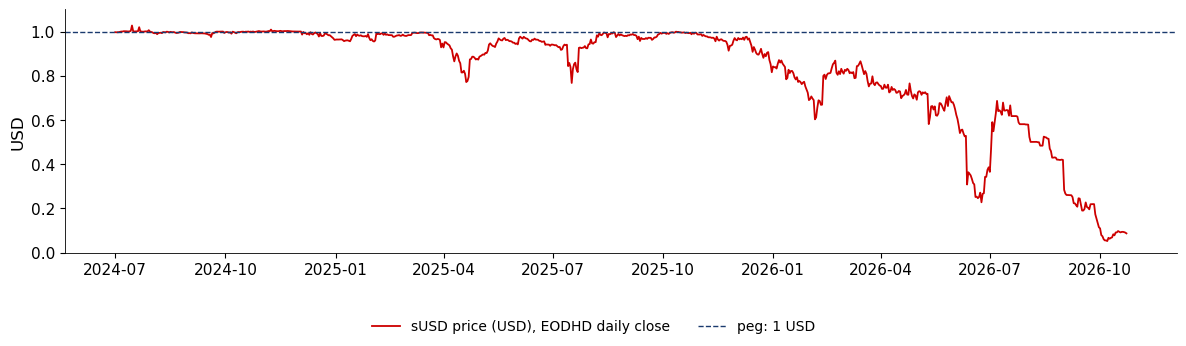

days below 0.99 USD since 1 January 2025: 607 of 661
first day below 0.95 USD after September 2025: 2025-11-24
sUSD close at quarter ends (USD): {'2025-03-31': 0.946, '2025-06-30': 0.941, '2025-09-30': 0.991, '2025-12-31': 0.816, '2026-03-31': 0.756, '2026-06-30': 0.386, '2026-09-30': 0.115, '2026-12-31': 0.088}
sUSD close on 2026-10-23: 0.09 USD


In [9]:
s = (1 + D['SUSD'] / 1e4).loc['2024-07-01':]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(s.index, s, color=RED, lw=1.3, label='sUSD price (USD), EODHD daily close')
ax.axhline(1, color=BLUE, ls='--', lw=1, label='peg: 1 USD')
ax.set_ylabel('USD'); ax.set_ylim(0, 1.1)
finish_fig(fig, 'ba_l6_susd', ncol=2, bottom=0.14)
s25 = s.loc['2025-01-01':]
print(f'days below 0.99 USD since 1 January 2025: {int((s25 < 0.99).sum())} of {len(s25)}')
print('first day below 0.95 USD after September 2025:', s.loc['2025-09-01':][s.loc['2025-09-01':] < 0.95].index[0].date())
print('sUSD close at quarter ends (USD):', {str(k.date()): round(v, 3) for k, v in P['SUSD'].resample('QE').last().loc['2025':].items()})
print(f'sUSD close on {s.index[-1].date()}: {s.iloc[-1]:.2f} USD')

Unlike the SVB weekend of Lecture 5 (two days), no arbitrage closes this gap, because redemption at par is not available: a depeg can be a slow default.

## 2. Quantile regression and the Lasso

### The check loss

The $\tau$-quantile minimises an asymmetric absolute loss ([Koenker & Bassett, 1978](https://doi.org/10.2307/1913643)):

$$ \rho_\tau(e) = e\,\big(\tau - \mathbb 1\{e < 0\}\big), \qquad q_\tau = \arg\min_q E\,\rho_\tau(Y - q). $$

Quantile regression solves $\min_{\alpha, \beta} \sum_i \rho_\tau(y_i - \alpha - \mathbf x_i'\beta)$, a linear programme.
For $\tau = 0.05$ a residual below the line costs $0.95|e|$ and one above it $0.05|e|$, so the fit is pushed to the lower tail.

Left: the check loss for three levels $\tau$. Right: the total loss $\sum_i \rho_\tau(y_i - q)$ of 20 daily deviations as a function of the candidate quantile $q$.

tau = 0.05: a minimiser of the total loss is q = -117.9 bp, minimum loss 116.55
tau = 0.5: a minimiser of the total loss is q = 2.0 bp, minimum loss 137.50


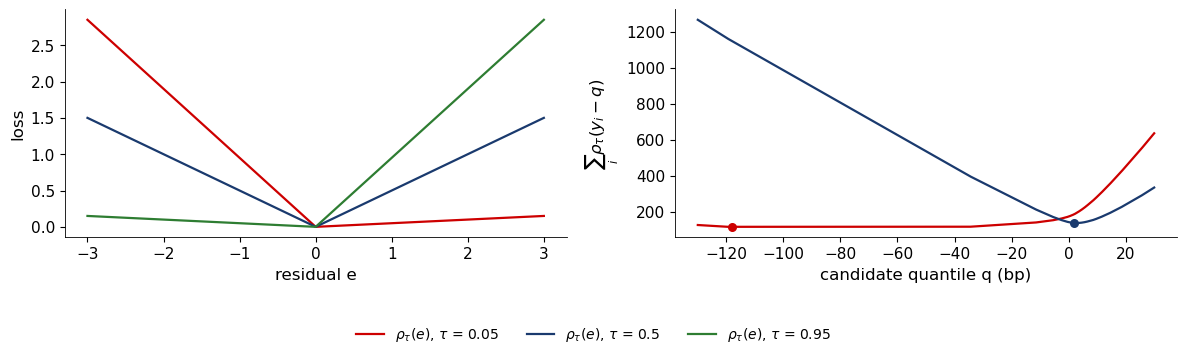

In [10]:
TAU = 0.05
check = lambda e, t: e * (t - (e < 0))
y20 = np.array([-120, -35, -12, -6, -3, -1, 0, 1, 2, 2, 3, 4, 5, 6, 8, 9, 11, 14, 18, 25])     # 20 daily deviations, bp
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
e = np.linspace(-3, 3, 400)
for t, col in [(0.05, RED), (0.5, BLUE), (0.95, GREEN)]:
    ax[0].plot(e, check(e, t), color=col, lw=1.6, label=fr'$\rho_\tau(e)$, $\tau$ = {t}')
ax[0].set_xlabel('residual e'); ax[0].set_ylabel('loss')
qgrid = np.linspace(-130, 30, 1601)
for t, col in [(0.05, RED), (0.5, BLUE)]:
    Lq = np.array([check(y20 - q, t).sum() for q in qgrid])
    ax[1].plot(qgrid, Lq, color=col, lw=1.6)
    k = np.argmin(Lq)
    ax[1].scatter([qgrid[k]], [Lq[k]], color=col, s=30, zorder=5)
    print(f'tau = {t}: a minimiser of the total loss is q = {qgrid[k]:.1f} bp, minimum loss {Lq[k]:.2f}')
ax[1].set_xlabel('candidate quantile q (bp)'); ax[1].set_ylabel(r'$\sum_i \rho_\tau(y_i - q)$')
finish_fig(fig, 'ba_l6_checkloss', ncol=3, bottom=0.15)

For $\tau = 0.5$ the minimum is the median (2 bp). For $\tau = 0.05$ the loss is *flat* between $-120$ and $-35$ bp.

### Worked example: observations defining a 5% quantile

With $n = 20$ and $\tau = 0.05$, $n\tau = 1$: one observation lies below the quantile.

In [11]:
for q in [-120, -80, -35, -12]:
    print(f'total check loss at q = {q} bp: {check(y20 - q, 0.05).sum():.2f}')
print(f'n tau in a 90-day window: {90 * 0.05}')

total check loss at q = -120 bp: 116.55
total check loss at q = -80 bp: 116.55
total check loss at q = -35 bp: 116.55
total check loss at q = -12 bp: 139.55
n tau in a 90-day window: 4.5


Any value between the smallest and the second-smallest observation is a valid 5% quantile: the estimate is not unique.
In a 90-day window $n\tau = 4.5$ is not an integer, so the minimiser is unique: the 5th smallest observation (below it the slope of the total loss is $4 - 4.5 < 0$, above it $5 - 4.5 > 0$). Still, five days carry the whole lower tail. Rolling 5% quantile models are noisy by construction: one day entering or leaving the window can move the estimate.
This is why the DPI is analysed in regimes and event windows, not day by day.

### Sensitivity of the 5% quantile to extreme days

The 5% quantile of the 90 days before each day $t$ (the 5th lowest deviation), for USDC and DAI, around the SVB weekend of March 2023.

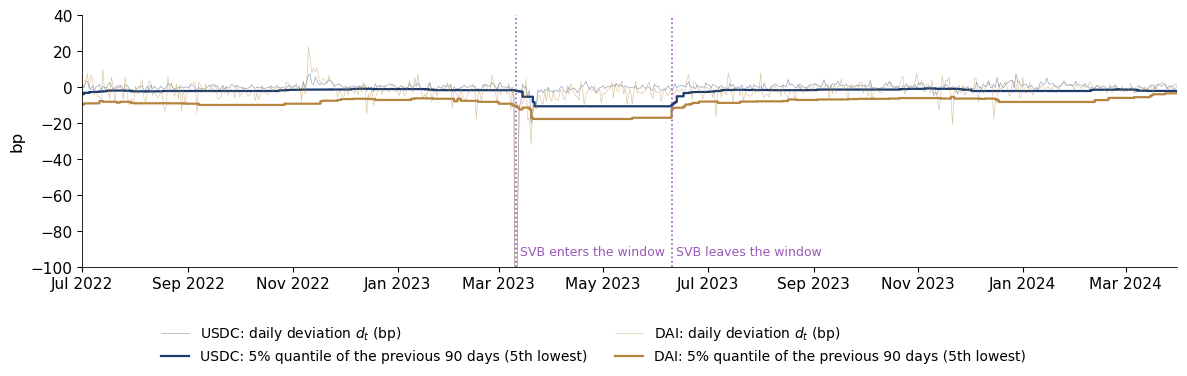

USDC daily deviations, 10-14 March 2023 (bp): {Timestamp('2023-03-10 00:00:00'): -5.2, Timestamp('2023-03-11 00:00:00'): -285.0, Timestamp('2023-03-12 00:00:00'): -79.3, Timestamp('2023-03-13 00:00:00'): -10.5, Timestamp('2023-03-14 00:00:00'): -8.2}


2023-03-11    -1.90
2023-03-12    -2.15
2023-03-15    -5.21
2023-03-22   -10.53
2023-06-09   -10.53
2023-06-13    -4.98
Name: USDC: 5% quantile of the 90 days before (bp), dtype: float64

In [12]:
q05 = D.rolling(90).quantile(0.05, interpolation='lower').shift(1)        # 5th lowest of the 90 days before t
fig, ax = plt.subplots(figsize=(12, 3.8))
for c, col in [('USDC', BLUE), ('DAI', GOLD)]:
    ax.plot(D.index, D[c], color=col, lw=0.5, alpha=0.45, label=f'{c}: daily deviation $d_t$ (bp)')
    ax.step(q05.index, q05[c], color=col, lw=1.6, where='post', label=f'{c}: 5% quantile of the previous 90 days (5th lowest)')
for t_, lab in [('2023-03-11', 'SVB enters the window'), ('2023-06-10', 'SVB leaves the window')]:
    ax.axvline(pd.Timestamp(t_), color=ETH, ls=':', lw=1.2)
    ax.text(pd.Timestamp(t_), -95, ' ' + lab, fontsize=9, color=ETH, va='bottom')
ax.set_xlim(pd.Timestamp('2022-07-01'), pd.Timestamp('2024-03-31')); ax.set_ylim(-100, 40); ax.set_ylabel('bp')
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter('%b %Y'))
finish_fig(fig, 'ba_l6_rollq', ncol=2, bottom=0.17)
print('USDC daily deviations, 10-14 March 2023 (bp):', D['USDC'].loc['2023-03-10':'2023-03-14'].round(1).to_dict())
pd.Series({d_: q05.loc[d_, 'USDC'] for d_ in ['2023-03-11', '2023-03-12', '2023-03-15', '2023-03-22', '2023-06-09', '2023-06-13']},
          name='USDC: 5% quantile of the 90 days before (bp)').round(2)

When the $-285$ bp close of 11 March enters the window, the 5% quantile of USDC moves only from $-1.90$ to $-2.15$ bp: it is the 5th lowest value, so one extreme day changes only its rank order.
It reaches $-5.2$ bp once four SVB days are among the five lowest, and stays at $-10.5$ bp until the SVB days leave the window in June. The size of the lowest day never enters the estimate, only its rank.

### Quantile Lasso and the selected penalty

With many candidate predictors we add an L1 penalty $\lambda\,\|\beta\|_1 = \lambda \sum_k |\beta_k|$ ([Tibshirani, 1996](https://doi.org/10.1111/j.2517-6161.1996.tb02080.x); [Belloni & Chernozhukov, 2011](https://doi.org/10.1214/10-AOS827)). For target coin $j$ and the window $W_t$ of the 90 days before day $t$:

$$ (\hat\alpha, \hat\beta)(\lambda) = \arg\min_{\alpha, \beta} \sum_{s \in W_t} \rho_{0.05}\big(d_{j,s} - \alpha - \mathbf x_{j,s}'\beta\big) + \lambda\,\|\beta\|_1 . $$

All slopes are zero for $\lambda \geq \lambda_{max}$, with $\psi_\tau(u) = \tau - \mathbb 1\{u < 0\}$ and

$$ \lambda_{max} = \max_k \Big|\sum_{s} x_{k,s}\,\psi_\tau\big(d_{j,s} - \hat q_\tau\big)\Big|, $$

a scaled covariance between each predictor and the target's lower-tail indicator. The penalty is chosen on a grid of 25 values from $10^{-4}\lambda_{max}$ to $\lambda_{max}$ by the generalised approximate cross-validation (GACV) criterion

$$ \mathrm{GACV}(\lambda) = \frac{\sum_s \rho_\tau\big(d_{j,s} - \hat\alpha - \mathbf x_{j,s}'\hat\beta(\lambda)\big)}{n - \mathrm{df}(\lambda)}, \qquad \mathrm{df} = \#\{\hat\beta_k \neq 0\} + 1, $$

where df are the degrees of freedom. The FRM idea: the selected $\hat\lambda_{j,t}$ is a risk measure; a higher $\hat\lambda$ means stronger tail co-movement under the fixed specification.

**Computation.** The Quantile Lasso is a linear programme. We solve its dual, which is smaller and gives the same solution:
$\max_z \mathbf y'z$ subject to $\mathbf 1'z = 0$, $|X'z| \leq \lambda$ and $\tau - 1 \leq z_s \leq \tau$; the slopes $\hat\beta$ and the intercept are the multipliers of the constraints.
Every variable is centred by its window median and divided by $1.4826 \times$ its median absolute deviation (MAD); the factor 1.4826 makes the MAD comparable to a standard deviation for Normal data.

In [13]:
WIN, NGRID, LO = 90, 25, 1e-4
DV, MV, MCOLS = D.values, M.values, list(M.columns)
DVraw = D_raw.values


def window(t_idx):
    """Deviations of the 90 days before t as known on day t: cleaned, except the last day, which cannot yet be checked."""
    Y = DV[t_idx - WIN:t_idx].copy()
    Y[-1] = DVraw[t_idx - 1]
    return Y


def qlasso(X, y, lam, tau=TAU):
    """5% Quantile Lasso via the dual linear programme; returns intercept and slopes."""
    n, p = X.shape
    r = linprog(-y, A_ub=np.vstack([X.T, -X.T]), b_ub=np.full(2 * p, lam), A_eq=np.ones((1, n)), b_eq=[0],
                bounds=(tau - 1, tau), method='highs-ds')
    m = r.ineqlin.marginals
    return -r.eqlin.marginals[0], m[p:] - m[:p]


def robust(Z):
    """Centre by the median, scale by 1.4826 MAD (by the sd if the MAD is zero); drop constant columns."""
    med = np.median(Z, axis=0)
    mad = 1.4826 * np.median(np.abs(Z - med), axis=0)
    s = np.where(mad > 0, mad, Z.std(axis=0))
    keep = s > 0
    return (Z[:, keep] - med[keep]) / s[keep], keep


def fit_eq(y, X, lo=LO):
    """GACV-selected penalty: returns (lambda, GACV, slopes, index of lambda on the grid)."""
    n = len(y)
    if X.shape[1] == 0:
        return np.nan, check(y - np.quantile(y, TAU), TAU).sum() / (n - 1), np.array([]), -1
    q0 = np.quantile(y, TAU)
    lmax = np.abs(X.T @ (TAU - (y < q0))).max()
    best = None
    for k, lam in enumerate(np.geomspace(lmax * lo, lmax, NGRID)):
        a, b = qlasso(X, y, lam)
        df = 1 + (np.abs(b) > 1e-8).sum()
        g = check(y - a - X @ b, TAU).sum() / (n - df)
        if best is None or g < best[1]:
            best = (lam, g, b, k)
    return best


def day(t_idx, blocks=('coin', 'macro'), lo=LO):
    """All coin equations on the window of the 90 days before calendar row t_idx."""
    Y = window(t_idx)
    out = {}
    for j, c in enumerate(COINS):
        y = Y[:, j]
        if np.isnan(y).any():
            continue
        y = (y - np.median(y)) / (1.4826 * np.median(np.abs(y - np.median(y))) or y.std() or 1)
        parts, names = [], []
        if 'coin' in blocks:
            others = [k for k in range(len(COINS)) if k != j]
            Xc = Y[:, others]
            ok = ~np.isnan(Xc).any(axis=0)
            parts.append(Xc[:, ok]); names += [COINS[k] for k, o in zip(others, ok) if o]
        if 'macro' in blocks:
            parts.append(MV[t_idx - WIN:t_idx]); names += MCOLS
        if parts:
            Zs, keep = robust(np.hstack(parts))
            names = [nm for nm, k in zip(names, keep) if k]
        else:
            Zs, names = np.empty((WIN, 0)), []
        lam, g, b, k = fit_eq(y, Zs, lo)
        out[c] = dict(lam=lam, gacv=g, k=k, coef=dict(zip(names, b)))
    return t_idx, out


N_JOBS = os.cpu_count() or 1


def days_chunk(ix, blocks, lo):
    return [day(i, blocks, lo) for i in ix]


def run_days(idx, blocks=('coin', 'macro'), lo=LO):
    """Estimate all equations on the calendar rows idx, in parallel on all cores (chunks of days per worker)."""
    chunks = [c for c in np.array_split(np.asarray(idx), 4 * N_JOBS) if len(c)]
    out = Parallel(n_jobs=N_JOBS)(delayed(days_chunk)(c, blocks, lo) for c in chunks)
    return {i: o for part in out for i, o in part}

### Worked example: the quantile Lasso equation for USDC after SVB

Target USDC, window of the 90 days to 19 March 2023, 13 candidate predictors (9 coins and 4 lagged market changes). Left: the coefficient path $\hat\beta_k(\lambda)$ (solid: coins, dashed: market variables). Right: GACV and the number of active predictors.

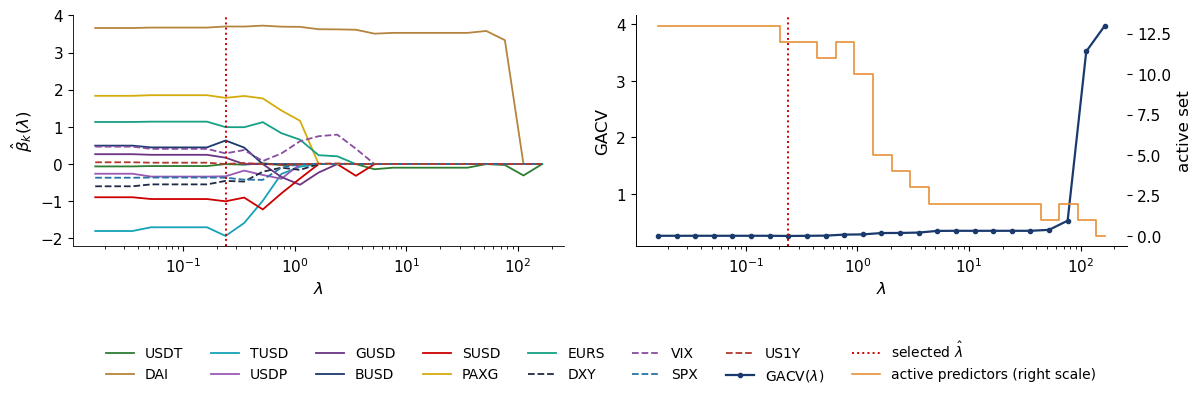

lambda_max = 164.1; selected lambda = 0.241 with 12 of 13 predictors active; minimum GACV = 0.2561


,slope at the selected lambda
DAI,3.702
TUSD,-1.933
PAXG,1.781
SUSD,-1.001
EURS,0.994
BUSD,0.634
DXY,-0.452
SPX,-0.366
USDP,-0.329
VIX,0.288


In [14]:
t_idx = cal.get_loc(pd.Timestamp('2023-03-20'))
w = slice(t_idx - WIN, t_idx)
j = COINS.index('USDC')
y = DV[w, j]
y = (y - np.median(y)) / (1.4826 * np.median(np.abs(y - np.median(y))))
names = [c for c in COINS if c != 'USDC'] + MCOLS
Zs, keep = robust(np.hstack([np.delete(DV[w], j, axis=1), MV[w]]))
names = [nm for nm, k in zip(names, keep) if k]
lmax = np.abs(Zs.T @ (TAU - (y < np.quantile(y, TAU)))).max()
grid = np.geomspace(lmax * LO, lmax, NGRID)
path, gac, dfs = [], [], []
for lam in grid:
    a, b = qlasso(Zs, y, lam)
    df = 1 + (np.abs(b) > 1e-8).sum()
    path.append(b); gac.append(check(y - a - Zs @ b, TAU).sum() / (len(y) - df)); dfs.append(df - 1)
path = np.array(path); kb = int(np.argmin(gac))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pal = [GREEN, GOLD, TEAL, ETH, '#6C3483', BLUE, RED, '#D4AC0D', '#16A085', NAVY, '#884EA0', '#2874A6', '#B03A2E']
for i, nm in enumerate(names):
    ax[0].plot(grid, path[:, i], color=pal[i % len(pal)], lw=1.3, ls='-' if nm in COINS else '--', label=nm)
ax[0].axvline(grid[kb], color=RED, ls=':', lw=1.4)
ax[0].set_xscale('log'); ax[0].set_xlabel(r'$\lambda$'); ax[0].set_ylabel(r'$\hat\beta_k(\lambda)$')
ax[1].plot(grid, gac, color=BLUE, lw=1.6, marker='o', ms=3, label=r'GACV($\lambda$)')
ax[1].axvline(grid[kb], color=RED, ls=':', lw=1.4, label=r'selected $\hat\lambda$')
ax2 = ax[1].twinx(); ax2.spines['top'].set_visible(False)
ax2.step(grid, dfs, color=BTC, where='mid', lw=1.2, label='active predictors (right scale)')
ax[1].set_xscale('log'); ax[1].set_xlabel(r'$\lambda$'); ax[1].set_ylabel('GACV'); ax2.set_ylabel('active set')
finish_fig(fig, 'ba_l6_lasso_path', ncol=8, bottom=0.2)
print(f'lambda_max = {lmax:.1f}; selected lambda = {grid[kb]:.3f} with {dfs[kb]} of {len(names)} predictors active; minimum GACV = {gac[kb]:.4f}')
pd.Series({nm: v for nm, v in zip(names, path[kb]) if abs(v) > 1e-8}).sort_values(key=abs, ascending=False).round(3).to_frame('slope at the selected lambda')

DAI keeps the largest slope along the path and is the only active predictor at $\lambda \approx 52$ (USDT enters first, alone, at $\lambda \approx 112$; DAI enters at $\lambda \approx 76$): in the SVB window, the lower tail of USDC was the lower tail of DAI.

## 3. The De-pegging Pressure Index

### Construction

For each coin $j$ and day $t$, a 5% Quantile Lasso on the preceding 90 days:

- target: $d_{j,s}$; predictors: the other coins' $d_{k,s}$ (same day) and the one-day-lagged changes of DXY, VIX, S&P 500 (log changes) and the 1-year yield (first differences); the paper also uses a crypto volatility index (CVIX);
- every variable centred by its window median and divided by $1.4826 \times \mathrm{MAD}$;
- 25 values of $\lambda$; $\hat\lambda_{j,t}$ minimises GACV.

The index is the average selected penalty:

$$ \mathrm{DPI}_t = \frac{1}{J}\sum_{j=1}^{J} \hat\lambda_{j,t} . $$

The DPI is *not* a depeg probability or a percentage; it is a model-implied measure of lower-tail dependence.

**Reduced computation.** The daily index from April 2020 to October 2026 needs about 24,000 equations, each on 25 penalties: some 600,000 linear programmes, which take more than half an hour on two processor cores.
Here we estimate the DPI **every 7th day** (the days before the weekly portfolio rebalancing used at the end), about 340 days, and **every day** only inside the windows around the six events analysed below.
The weekly series is enough for the chart, the annual medians and the trend; the event responses use daily values.
With two processor cores (as on Colab) the estimation cells below take about 5 minutes in total.
Set `FULL_DAILY = True` to estimate every day, as in the lecture.

In [15]:
import time
FULL_DAILY = False

EVENTS = {'KuCoin hack': '2020-09-26', 'China sell-off': '2021-05-19', 'Terra collapse': '2022-05-09',
          'FTX crisis': '2022-11-08', 'SVB / USDC depeg': '2023-03-11', 'Iran-Hormuz shock': '2026-02-28'}
first = cal.get_loc(pd.Timestamp('2020-04-01'))
weekly = [i for i in range(first, len(cal)) if (cal[i] - pd.Timestamp('2020-06-29')).days % 7 == 0]
ev_days = sorted({cal.get_loc(t_) for d0 in EVENTS.values()
                  for t_ in pd.date_range(pd.Timestamp(d0) - pd.Timedelta(days=60), pd.Timestamp(d0) + pd.Timedelta(days=30))})
idx = list(range(first, len(cal))) if FULL_DAILY else sorted(set(weekly) | set(ev_days))
t0 = time.time()
res = run_days(idx)
print(f'{len(idx)} days x {len(COINS)} coins estimated in {time.time() - t0:.0f} s')
LAM = pd.DataFrame({cal[i]: {c: v['lam'] for c, v in o.items()} for i, o in res.items()}).T[COINS].sort_index()
DPI_all = LAM.mean(axis=1)
DPI = DPI_all.loc[[cal[i] for i in weekly]] if not FULL_DAILY else DPI_all
FREQ = 'daily' if FULL_DAILY else 'weekly'
print(f'DPI series used for the chart and trend: {len(DPI)} days, {DPI.index[0].date()} to {DPI.index[-1].date()}; median {DPI.median():.3f}')
print('annual medians of the DPI:', DPI.groupby(DPI.index.year).median().round(2).to_dict())

810 days x 10 coins estimated in 42 s
DPI series used for the chart and trend: 342 days, 2020-04-06 to 2026-10-19; median 0.391
annual medians of the DPI: {2020: 0.26, 2021: 0.41, 2022: 0.39, 2023: 0.39, 2024: 0.42, 2025: 0.6, 2026: 0.34}


### The DPI, April 2020 – October 2026

Points are coloured by the quintile of the DPI (the five 20% bands of its distribution, from "low" to "severe"); dotted lines mark the six events.

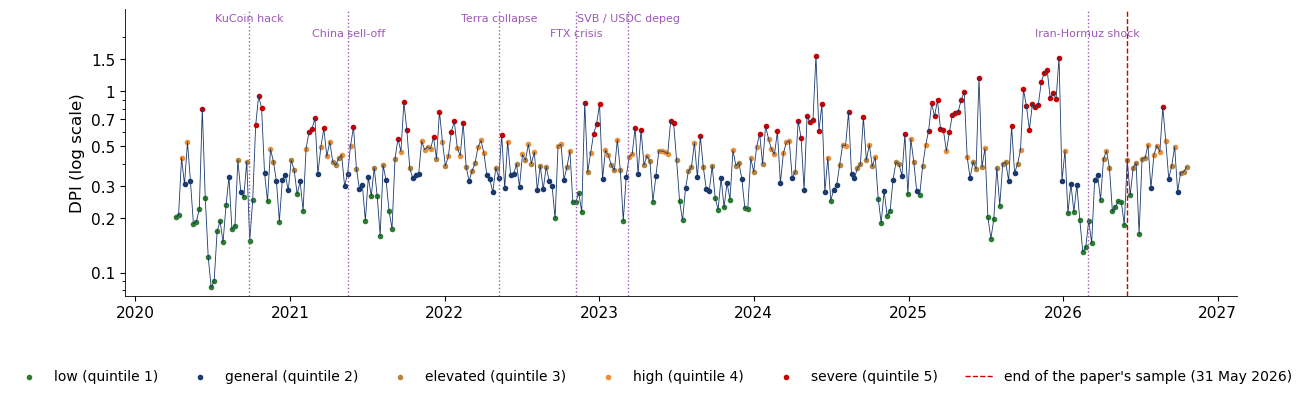

In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
qs = DPI.quantile([0.2, 0.4, 0.6, 0.8]).values
cats = np.digitize(DPI.values, qs)
qcols = [GREEN, BLUE, GOLD, BTC, RED]; labs = ['low', 'general', 'elevated', 'high', 'severe']
ax.plot(DPI.index, DPI.values, color=BLUE, lw=0.6)
for k in range(5):
    m = cats == k
    ax.scatter(DPI.index[m], DPI.values[m], s=9, color=qcols[k], label=f'{labs[k]} (quintile {k + 1})')
for k_, (name, d0) in enumerate(EVENTS.items()):
    ax.axvline(pd.Timestamp(d0), color=ETH, ls=':', lw=1)
    ax.text(pd.Timestamp(d0), DPI.max() * (1.25 if k_ % 2 else 1.5), name, fontsize=8, color=ETH, ha='center', va='bottom')
ax.axvline(pd.Timestamp(END_PAPER), color=RED, ls='--', lw=1, label="end of the paper's sample (31 May 2026)")
ax.set_yscale('log'); ax.set_ylabel('DPI (log scale)'); ax.set_ylim(DPI.min() * 0.9, DPI.max() * 1.8)
ax.set_yticks([0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5])
ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g')); ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
finish_fig(fig, 'ba_l6_dpi', ncol=6, bottom=0.14)

The DPI moves in regimes; its highest regime in late 2025 is carried mostly by BUSD (63% of the index in October–December 2025), not by the sUSD depeg of the same months.

Is there a secular trend? We regress $\ln \mathrm{DPI}_t$ on time in years up to May 2026 and use heteroskedasticity and autocorrelation consistent (HAC) standard errors (SE), with a lag window of about 90 days (13 weekly observations).

In [17]:
ld_ = np.log(DPI.loc[:END_PAPER])
tt = (ld_.index - ld_.index[0]).days.values / 365.25
lags = 90 if FULL_DAILY else 13
trd = sm.OLS(ld_.values, sm.add_constant(tt)).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
ci_ = trd.conf_int(0.05)[1]
print(f'trend of log DPI: {trd.params[1]:+.3f} per year (HAC SE {trd.bse[1]:.3f}, 95% CI [{ci_[0]:.3f}, {ci_[1]:.3f}], p-value {trd.pvalues[1]:.2f}); working paper: -0.004 per year, p-value 0.78')

trend of log DPI: +0.052 per year (HAC SE 0.040, 95% CI [-0.026, 0.130], p-value 0.19); working paper: -0.004 per year, p-value 0.78


We do not reject a zero slope in this specification. That is not evidence of no trend: the 95% interval is wide. What the replication shares with the paper is only the lack of significance; the signs differ.

### Worked example: the DPI on 12 March 2023

The ten selected penalties of 12 March 2023, each from the 90 days to 11 March (this day is estimated daily because it lies in the SVB event window), their mean, and the quintile of the DPI it falls in.

In [18]:
t_ = pd.Timestamp('2023-03-12')
lam12 = LAM.loc[t_]
print('selected penalties:', lam12.round(3).to_dict())
print(f'sum {lam12.sum():.3f}; DPI = {lam12.sum():.3f} / {lam12.count()} = {lam12.mean():.3f}')
print(f'quintile bounds of the {FREQ} DPI series: {np.round(DPI.quantile([0.2, 0.4, 0.6, 0.8]).values, 3)} (daily series of the lecture: 0.275, 0.350, 0.427, 0.550)')
top3 = lam12.sort_values().iloc[-3:]
print(f'three largest ({", ".join(top3.index[::-1])}): {100 * top3.sum() / lam12.sum():.0f}% of the sum; median penalty {lam12.median():.2f}')
print(f'without GUSD: ({lam12.sum():.3f} - {lam12["GUSD"]:.3f}) / 9 = {lam12.drop("GUSD").mean():.3f}')

selected penalties: {'USDT': 1.096, 'USDC': 0.902, 'DAI': 0.861, 'TUSD': 0.11, 'USDP': 0.586, 'GUSD': 1.369, 'BUSD': 0.045, 'SUSD': 0.072, 'PAXG': 0.05, 'EURS': 0.144}
sum 5.235; DPI = 5.235 / 10 = 0.524
quintile bounds of the weekly DPI series: [0.276 0.356 0.428 0.549] (daily series of the lecture: 0.275, 0.350, 0.427, 0.550)
three largest (GUSD, USDT, USDC): 64% of the sum; median penalty 0.36
without GUSD: (5.235 - 1.369) / 9 = 0.430


The DPI is a mean of skewed numbers: three coins carry about two thirds of the sum, and dropping one of them moves the index from the top of its quintile to the bottom.

### Contributions of individual coins to the DPI

Each coin contributes $\hat\lambda_{j,t}/J$ to $\mathrm{DPI}_t$. Left: the share of each coin in the yearly mean of the DPI. Right: the annual median of the DPI with all ten coins and without BUSD.

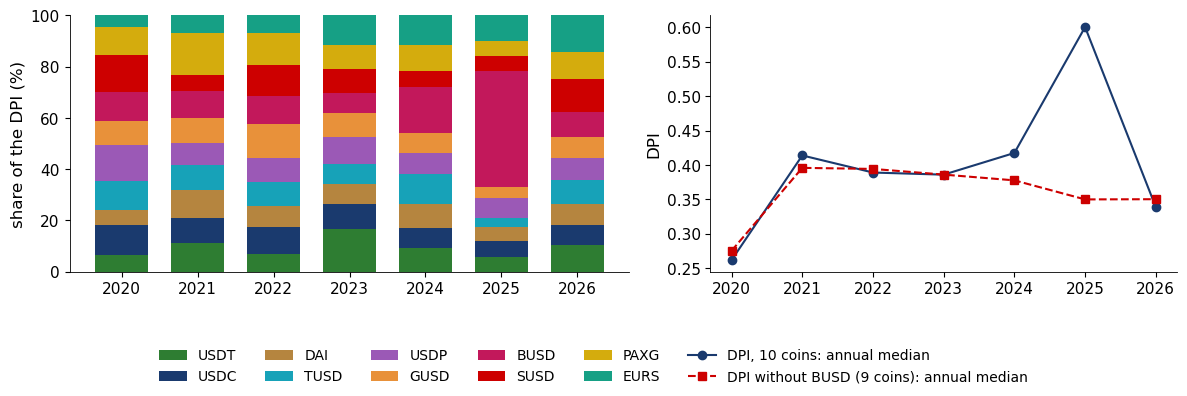

BUSD share of the DPI in 2025: 45.5%; October-December 2025: median DPI 0.91, without BUSD 0.32
standard deviation of the BUSD deviation by year (bp): {2023: 5.1, 2024: 34.8, 2025: 84.5, 2026: 6.6}


,2020,2021,2022,2023,2024,2025,2026
"DPI, 10 coins",0.26,0.41,0.39,0.39,0.42,0.60,0.34
DPI without BUSD,0.28,0.40,0.39,0.39,0.38,0.35,0.35


In [19]:
LAMp = LAM.loc[DPI.index]                                    # the days of the DPI series (weekly unless FULL_DAILY)
share = LAMp.div(LAMp.count(axis=1), axis=0)
yrs_ = share.groupby(share.index.year).mean()
yrs_ = 100 * yrs_.div(yrs_.sum(axis=1), axis=0)
DPI_x = LAMp.drop(columns='BUSD').mean(axis=1)
ann_ = pd.DataFrame({'DPI, 10 coins': DPI.groupby(DPI.index.year).median(), 'DPI without BUSD': DPI_x.groupby(DPI_x.index.year).median()})
ccol = dict(zip(COINS, [GREEN, BLUE, GOLD, TEAL, ETH, BTC, '#C2185B', RED, '#D4AC0D', '#16A085']))
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1.2, 1]})
bot = np.zeros(len(yrs_))
for c in COINS:
    ax[0].bar(yrs_.index, yrs_[c], bottom=bot, color=ccol[c], label=c, width=0.7)
    bot += yrs_[c].values
ax[0].set_ylabel('share of the DPI (%)'); ax[0].set_ylim(0, 100); ax[0].set_xticks(yrs_.index)
ax[1].plot(ann_.index, ann_.iloc[:, 0], color=BLUE, marker='o', lw=1.5, label='DPI, 10 coins: annual median')
ax[1].plot(ann_.index, ann_.iloc[:, 1], color=RED, marker='s', lw=1.5, ls='--', label='DPI without BUSD (9 coins): annual median')
ax[1].set_xticks(ann_.index); ax[1].set_ylabel('DPI')
finish_fig(fig, 'ba_l6_dpi_coins', ncol=6, bottom=0.2)
q4 = slice('2025-10-01', '2025-12-31')
print(f'BUSD share of the DPI in 2025: {yrs_.loc[2025, "BUSD"]:.1f}%; October-December 2025: median DPI {DPI.loc[q4].median():.2f}, without BUSD {DPI_x.loc[q4].median():.2f}')
print('standard deviation of the BUSD deviation by year (bp):', {y_: round(D['BUSD'].loc[str(y_)].std(), 1) for y_ in [2023, 2024, 2025, 2026]})
ann_.round(2).T

Most coins carry about a tenth of the index in most years. In 2025 BUSD alone carries about 40%: Paxos stopped minting BUSD in February 2023, and the deviations of this thinly traded token became very noisy. Without BUSD the high regime of late 2025 disappears.
With the weekly series the shares and medians differ slightly from the slide, which uses every day. Before reading a regime of the DPI, check indices that leave out one coin at a time.

### Event responses

The response to an event is the change of the mean DPI over days 0 to 30 relative to days $-60$ to $-8$:

$$ \Delta = \overline{\mathrm{DPI}}_{[0, 30]} \big/ \overline{\mathrm{DPI}}_{[-60, -8]} - 1 . $$

The test regresses $\ln \mathrm{DPI}$ in the two windows on a post-event dummy, with HAC errors (30 lags); the Holm correction adjusts the six p-values for multiple testing.
To see how fragile these numbers are, we repeat the estimation with a narrower grid of penalties, $[10^{-2}, 1]\,\lambda_{max}$.

In [20]:
def responses(dpi):
    rows = {}
    for name, d0 in EVENTS.items():
        t0_ = pd.Timestamp(d0)
        pre = dpi.loc[t0_ - pd.Timedelta(days=60):t0_ - pd.Timedelta(days=8)]
        post = dpi.loc[t0_:t0_ + pd.Timedelta(days=30)]
        seg = np.log(pd.concat([pre, post]))
        dm = np.r_[np.zeros(len(pre)), np.ones(len(post))]
        fr = sm.OLS(seg.values, sm.add_constant(dm)).fit(cov_type='HAC', cov_kwds={'maxlags': 30})
        rows[name] = {'date': d0, 'change (%)': 100 * (post.mean() / pre.mean() - 1), 't-statistic': fr.tvalues[1], 'p-value': fr.pvalues[1]}
    out = pd.DataFrame(rows).T
    out['Holm p-value'] = multipletests(out['p-value'].astype(float), method='holm')[1]
    return out


DPI_ev = DPI_all.loc[[cal[i] for i in ev_days]]          # daily DPI inside the event windows
EV = responses(DPI_ev)
t0 = time.time()
res_n = run_days(ev_days, lo=1e-2)                       # narrow grid, same days
DPIn = pd.DataFrame({cal[i]: {c: v['lam'] for c, v in o.items()} for i, o in res_n.items()}).T[COINS].sort_index().mean(axis=1)
print(f'narrow grid estimated in {time.time() - t0:.0f} s')
EV['change, narrow grid (%)'] = responses(DPIn)['change (%)']
EV['working paper: change (%)'] = pd.Series({'KuCoin hack': -14.4, 'China sell-off': -8.6, 'Terra collapse': 2.2, 'FTX crisis': 19.5,
                                     'SVB / USDC depeg': 11.0, 'Iran-Hormuz shock': -22.9})
EV.round(3)

narrow grid estimated in 30 s


,date,change (%),t-statistic,p-value,Holm p-value,"change, narrow grid (%)",working paper: change (%)
KuCoin hack,2020-09-26,141.773606,5.423794,0.0,0.000,94.888057,-14.4
China sell-off,2021-05-19,-20.024841,-2.636948,0.008366,0.033,-11.841703,-8.6
Terra collapse,2022-05-09,18.136215,2.831535,0.004633,0.023,15.535518,2.2
FTX crisis,2022-11-08,13.523871,0.715972,0.474009,0.948,36.988539,19.5
SVB / USDC depeg,2023-03-11,21.01666,2.158366,0.030899,0.093,158.609888,11.0
Iran-Hormuz shock,2026-02-28,2.223522,0.200923,0.840759,0.948,2.038542,-22.9


In the paper, the DPI rose significantly only after FTX and SVB, the two events about intermediation and reserve confidence (the paper's Terra response is not significant).
In this replication the sign agrees with the paper for 4 of the 6 events, but sizes and significance change with the data source and even with the grid of penalties.

### Event windows, day by day

The DPI divided by its mean over days $-60$ to $-8$, with a 7-day centred mean, for the six events (daily values inside the event windows).

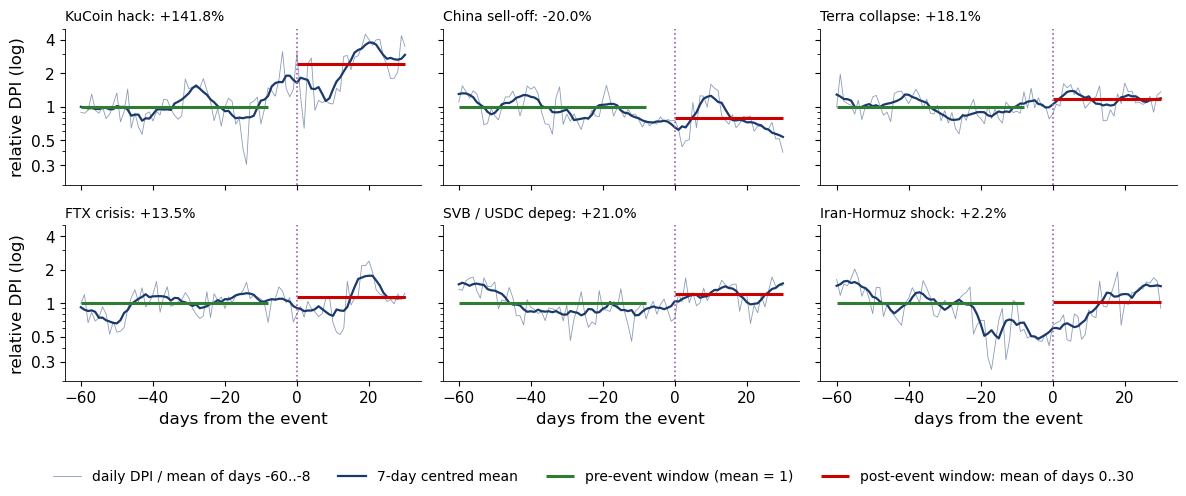

SVB: post-event days above the pre-event mean: 24 of 31


In [21]:
fig, axs = plt.subplots(2, 3, figsize=(12, 5), sharex=True, sharey=True)
for ax, (name, d0) in zip(axs.ravel(), EVENTS.items()):
    t0_ = pd.Timestamp(d0)
    pre_m = DPI_ev.loc[t0_ - pd.Timedelta(days=60):t0_ - pd.Timedelta(days=8)].mean()
    post_m = DPI_ev.loc[t0_:t0_ + pd.Timedelta(days=30)].mean()
    rel = DPI_ev.loc[t0_ - pd.Timedelta(days=60):t0_ + pd.Timedelta(days=30)] / pre_m
    xd = (rel.index - t0_).days
    first = name == 'KuCoin hack'
    ax.plot(xd, rel, color=BLUE, lw=0.6, alpha=0.5, label=('daily DPI / mean of days -60..-8' if first else None))
    ax.plot(xd, rel.rolling(7, center=True, min_periods=4).mean(), color=BLUE, lw=1.6, label=('7-day centred mean' if first else None))
    ax.hlines(1, -60, -8, color=GREEN, lw=2.2, label=('pre-event window (mean = 1)' if first else None))
    ax.hlines(post_m / pre_m, 0, 30, color=RED, lw=2.2, label=('post-event window: mean of days 0..30' if first else None))
    ax.axvline(0, color=ETH, ls=':', lw=1.2)
    ax.set_title(f'{name}: {100 * (post_m / pre_m - 1):+.1f}%', fontsize=10, loc='left'); ax.set_yscale('log')
for ax in axs[1]:
    ax.set_xlabel('days from the event')
for ax in axs[:, 0]:
    ax.set_ylabel('relative DPI (log)')
axs[0, 0].set_ylim(0.2, 5); axs[0, 0].set_yticks([0.3, 0.5, 1, 2, 4])
axs[0, 0].yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g')); axs[0, 0].yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
finish_fig(fig, 'ba_l6_eventpaths', ncol=4, bottom=0.1)
t0_ = pd.Timestamp('2023-03-11')
print('SVB: post-event days above the pre-event mean:',
      int((DPI_ev.loc[t0_:t0_ + pd.Timedelta(days=30)] > DPI_ev.loc[t0_ - pd.Timedelta(days=60):t0_ - pd.Timedelta(days=8)].mean()).sum()), 'of 31')

The paths differ in timing and shape: after KuCoin the DPI was already rising before day 0 and kept rising; around the China sell-off and Iran–Hormuz there is no step at day 0. A ratio of two window means compresses all of this into one number.

### Worked example: the SVB response by hand

In [22]:
t0_ = pd.Timestamp('2023-03-11')
pre = DPI_ev.loc[t0_ - pd.Timedelta(days=60):t0_ - pd.Timedelta(days=8)]
post = DPI_ev.loc[t0_:t0_ + pd.Timedelta(days=30)]
print(f'pre-event window {pre.index[0].date()} to {pre.index[-1].date()}: {len(pre)} days, sum {pre.sum():.2f}, mean {pre.sum():.2f} / {len(pre)} = {pre.mean():.3f}')
print(f'post-event window {post.index[0].date()} to {post.index[-1].date()}: {len(post)} days, sum {post.sum():.2f}, mean {post.sum():.2f} / {len(post)} = {post.mean():.3f}')
print(f'response = {post.mean():.3f} / {pre.mean():.3f} - 1 = {100 * (post.mean() / pre.mean() - 1):+.1f}%')
print(f'difference of the window means of ln DPI: {np.log(post).mean() - np.log(pre).mean():.3f}')
print(f'with medians: {pre.median():.3f} -> {post.median():.3f}, {100 * (post.median() / pre.median() - 1):+.0f}%')

pre-event window 2023-01-10 to 2023-03-03: 53 days, sum 22.56, mean 22.56 / 53 = 0.426
post-event window 2023-03-11 to 2023-04-10: 31 days, sum 15.97, mean 15.97 / 31 = 0.515
response = 0.515 / 0.426 - 1 = +21.0%
difference of the window means of ln DPI: 0.212
with medians: 0.386 -> 0.514, +33%


The response is a ratio of two means; the test uses the logs, which give almost the same number here. With medians the response is $+33\%$ instead of $+21\%$: the size depends on the summary statistic, as well as on the grid of penalties.

### Robustness of event responses

event-window days: share of equations that select the smallest lambda (boundary solution): wide grid 9.4%, narrow grid 18.9%
correlation of log DPI, wide vs narrow grid, event-window days: 0.81


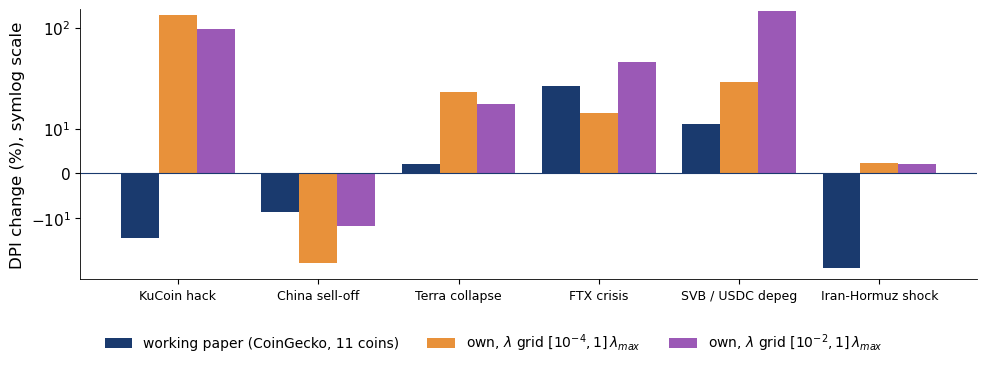

In [23]:
edge_w = np.mean([v['k'] == 0 for i in ev_days for v in res[i].values()])
edge_n = np.mean([v['k'] == 0 for o in res_n.values() for v in o.values()])
print(f'event-window days: share of equations that select the smallest lambda (boundary solution): wide grid {100 * edge_w:.1f}%, narrow grid {100 * edge_n:.1f}%')
print(f'correlation of log DPI, wide vs narrow grid, event-window days: {np.corrcoef(np.log(DPI_ev), np.log(DPIn))[0, 1]:.2f}')

fig, ax = plt.subplots(figsize=(10, 3.7))
xx = np.arange(len(EVENTS))
ax.bar(xx - 0.27, EV['working paper: change (%)'].astype(float), width=0.27, color=BLUE, label='working paper (CoinGecko, 11 coins)')
ax.bar(xx, EV['change (%)'].astype(float), width=0.27, color=BTC, label=r'own, $\lambda$ grid $[10^{-4}, 1]\,\lambda_{max}$')
ax.bar(xx + 0.27, EV['change, narrow grid (%)'].astype(float), width=0.27, color=ETH, label=r'own, $\lambda$ grid $[10^{-2}, 1]\,\lambda_{max}$')
ax.axhline(0, color=BLUE, lw=0.8)
ax.set_xticks(xx); ax.set_xticklabels(list(EVENTS), fontsize=9); ax.set_ylabel('DPI change (%), symlog scale')
ax.set_yscale('symlog', linthresh=20)                    # linear within +-20%, logarithmic beyond
finish_fig(fig, 'ba_l6_events', ncol=3, bottom=0.12)

With the narrow grid many more equations end at the smallest penalty, a boundary solution. The two indices are highly correlated, yet the SVB response is $+21\%$ in one specification and $+159\%$ in the other: a 31-day mean of a noisy index is sensitive to tuning choices.
Event responses should be reported together with their specification; results that survive several specifications deserve more trust.

## 4. Tail dependence between stablecoins

### Tail links between stablecoins: signed selection frequencies

A positive slope is **aligned**: a lower deviation of the predictor coin goes with a lower 5% quantile of the target coin; a negative slope is **inverse**.
For each pair (target, predictor) we count how often the slope is aligned and how often inverse, over the weekly equations, and report the difference in percentage points (pp) of all equations of that target: a *signed selection frequency*. It counts selections; it does not measure how many bp one coin passes to another.

coin coefficients: aligned 47.4%, inverse 33.2% (working paper: 39.6% and 23.9%)
market variables: 18.6% of the absolute slope weight (working paper: 20.8%); mean active set 10.31 predictors


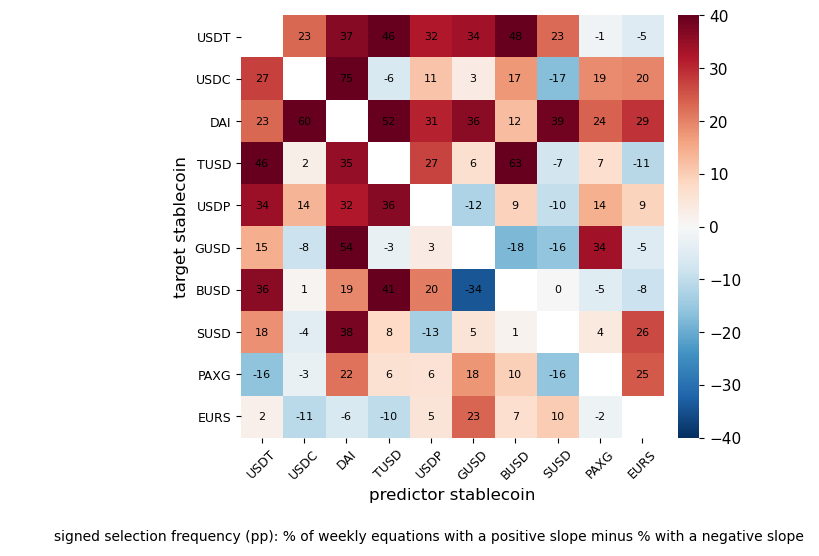

strongest aligned links (target <- predictor, pp): {'USDC <- DAI': 75, 'TUSD <- BUSD': 63, 'DAI <- USDC': 60, 'GUSD <- DAI': 54}
most inverse links (target <- predictor, pp): {'USDC <- SUSD': -17, 'GUSD <- BUSD': -18, 'BUSD <- GUSD': -34}


In [24]:
wres = {i: res[i] for i in weekly}
A = pd.DataFrame(0.0, index=COINS, columns=COINS); I_ = A.copy(); N_ = A.copy()
pos = neg = tot = 0
act, mac_w = [], []
for o in wres.values():
    for c, v in o.items():
        cf = v['coef']
        act.append(sum(abs(x) > 1e-8 for x in cf.values()))
        s_all = sum(abs(x) for x in cf.values())
        if s_all > 0:
            mac_w.append(sum(abs(cf.get(m, 0)) for m in MCOLS) / s_all)
        for k in COINS:
            if k == c:
                continue
            N_.loc[c, k] += 1
            x = cf.get(k, 0.0)
            A.loc[c, k] += x > 1e-8; I_.loc[c, k] += x < -1e-8
            if k in cf:
                tot += 1; pos += x > 1e-8; neg += x < -1e-8
Lk = 100 * (A - I_) / N_.replace(0, np.nan)
print(f'coin coefficients: aligned {100 * pos / tot:.1f}%, inverse {100 * neg / tot:.1f}% (working paper: 39.6% and 23.9%)')
print(f'market variables: {100 * np.mean(mac_w):.1f}% of the absolute slope weight (working paper: 20.8%); mean active set {np.mean(act):.2f} predictors')

fig, ax = plt.subplots(figsize=(8, 5.6))
im = ax.imshow(Lk.values, cmap='RdBu_r', vmin=-40, vmax=40)
for a in range(len(COINS)):
    for b in range(len(COINS)):
        if a != b:
            ax.text(b, a, f'{Lk.values[a, b]:.0f}', ha='center', va='center', fontsize=8)
ax.set_xticks(range(len(COINS))); ax.set_xticklabels(COINS, fontsize=9, rotation=45)
ax.set_yticks(range(len(COINS))); ax.set_yticklabels(COINS, fontsize=9)
ax.set_xlabel('predictor stablecoin'); ax.set_ylabel('target stablecoin')
for sp in ax.spines.values():
    sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.outline.set_visible(False)
ax.plot([], [], color='none', label='signed selection frequency (pp): % of weekly equations with a positive slope minus % with a negative slope')
finish_fig(fig, 'ba_l6_links', ncol=1, bottom=0.06)
top = Lk.stack().sort_values(ascending=False)
print('strongest aligned links (target <- predictor, pp):', {f'{a} <- {b}': round(v) for (a, b), v in top.head(4).items()})
print('most inverse links (target <- predictor, pp):', {f'{a} <- {b}': round(v) for (a, b), v in top.tail(3).items()})

Aligned links outnumber inverse ones, and the strongest pairs are economically plausible (USDC and DAI, which shared collateral; TUSD and BUSD).
In the paper no pair difference survives multiple testing, and the rankings change between the two halves of the sample: a common structure, with no fixed sender of pressure.

### Model sparsity across DPI quintiles

The mean number of active predictors (out of 13) in each DPI quintile:

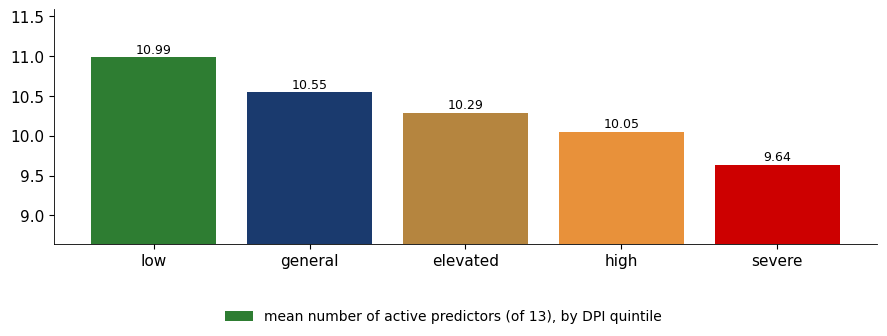

mean active set by DPI quintile: {'low': 10.99, 'general': 10.55, 'elevated': 10.29, 'high': 10.05, 'severe': 9.64} ; working paper: 10.11 (lowest) to 9.00 (highest), of 15


In [25]:
act_day = pd.Series({cal[i]: np.mean([sum(abs(x) > 1e-8 for x in v['coef'].values()) for v in o.values()]) for i, o in wres.items()})
qd = pd.qcut(DPI, 5, labels=labs)
mq = act_day.reindex(DPI.index).groupby(qd).mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(mq.index.astype(str), mq.values, color=qcols, label='mean number of active predictors (of 13), by DPI quintile')
for i, v_ in enumerate(mq.values):
    ax.text(i, v_ + 0.05, f'{v_:.2f}', ha='center', fontsize=9)
ax.set_ylim(mq.min() - 1, mq.max() + 0.6)
finish_fig(fig, 'ba_l6_active', ncol=1, bottom=0.14)
print('mean active set by DPI quintile:', mq.round(2).to_dict(), '; working paper: 10.11 (lowest) to 9.00 (highest), of 15')

Part of this is mechanical: a larger selected penalty removes predictors by construction. The economic reading, that under pressure a few strong tail links dominate, is a hypothesis this chart does not test. The direction is the same as in the paper, one of the results that survives replication.

### The DPI and simple stress gauges

Two simple gauges over the same 90-day window as the DPI: the mean of the cross-coin median $|d_{i,t}|$ (prices as recorded) and the mean VIX. Each point is one day of the DPI series.

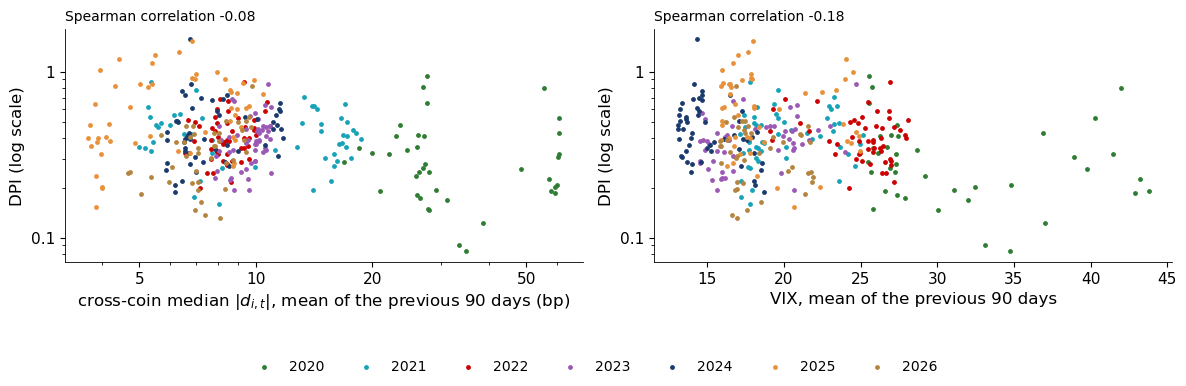

342 weekly values; Spearman correlation of the DPI with the median |d|: -0.08, with the VIX: -0.18 (daily series of the lecture: -0.10 and -0.16)


In [26]:
from scipy.stats import spearmanr
ext = pd.DataFrame({'dpi': DPI,
                    'absd': D_raw.abs().median(axis=1).rolling(WIN).mean().shift(1).reindex(DPI.index),
                    'vix': mac['VIX'].rolling(WIN).mean().shift(1).reindex(DPI.index)}).dropna()
sp_ = {k: spearmanr(ext['dpi'], ext[k])[0] for k in ['absd', 'vix']}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
ycol = {2020: GREEN, 2021: TEAL, 2022: RED, 2023: ETH, 2024: BLUE, 2025: BTC, 2026: GOLD}
for y_, col in ycol.items():
    m = ext.index.year == y_
    ax[0].scatter(ext.loc[m, 'absd'], ext.loc[m, 'dpi'], s=6, color=col, label=str(y_))
    ax[1].scatter(ext.loc[m, 'vix'], ext.loc[m, 'dpi'], s=6, color=col)
ax[0].set_xscale('log'); ax[0].set_xticks([5, 10, 20, 50])
ax[0].xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g')); ax[0].xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax[0].set_xlabel(r'cross-coin median $|d_{i,t}|$, mean of the previous 90 days (bp)'); ax[1].set_xlabel('VIX, mean of the previous 90 days')
for a_, k in zip(ax, ['absd', 'vix']):
    a_.set_yscale('log'); a_.set_ylabel('DPI (log scale)'); a_.set_title(f'Spearman correlation {sp_[k]:.2f}', fontsize=10, loc='left')
    a_.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g')); a_.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
finish_fig(fig, 'ba_l6_stress', ncol=7, bottom=0.14)
print(f'{len(ext)} {FREQ} values; Spearman correlation of the DPI with the median |d|: {sp_["absd"]:.2f}, with the VIX: {sp_["vix"]:.2f} '
      '(daily series of the lecture: -0.10 and -0.16)')

The DPI is almost unrelated to how far the coins are from their pegs and to equity-market fear: 2020 has the largest deviations and the highest VIX, but a low DPI.
The DPI measures how coins move together in their lower tails; it complements simple gauges, it does not replace them.

### In-sample fit, out-of-sample forecasts and concentration (results of the working paper)

Two further results of the paper need data that are not in the course repository (held-out forecasts with on-chain variables, market capitalisations), so we only report them:

| Model | in-window GACV skill | same-day OOS nowcast skill | fully lagged OOS forecast skill |
|---|---:|---:|---:|
| market variables only | 8.3% | −12.5% | −12.5% |
| coins only | 33.7% | −15.9% | −34.4% |
| joint | 37.0% | −19.8% | −38.6% |

Skill is $1 -$ (loss of the model) / (loss of the intercept-only model), on the paper's sample to 31 May 2026; a negative value means worse than that benchmark. The first column is the GACV inside each 90-day estimation window, not a held-out loss; the other two are check losses on days outside the estimation window (out-of-sample, OOS), with coin predictors from the target's own day (nowcast) or with every predictor dated $t-1$ (forecast).
The best in-window description (joint, 37%) is the worst forecast once the predictors are dated $t-1$; the DPI alone has a negative out-of-sample (OOS) $R^2$ at horizons from 10 to 150 days.

The normalised Herfindahl–Hirschman index of the paper's $J = 11$ coins, $(\mathrm{HHI} - 1/J)/(1 - 1/J)$ with $\mathrm{HHI} = \sum_j s_j^2$ and $s_j$ the market-value share within the 11 coins (not comparable with the raw HHI of Lecture 1), has no significant link with the DPI once year effects are included: $+1$ standard deviation (SD) of the HHI goes with a $-1.52\%$ change of the DPI, 95% interval $[-4.24\%, 1.27\%]$.
Concentration tells you *how much* of the system depends on two issuers; it does not tell you *when* pressure builds.

## Further material

### Data check: bad prints

The prints removed by the rule in the data section, largest moves first:

In [27]:
FLAGS.assign(abs_move=FLAGS['log return (bp)'].abs()).sort_values('abs_move', ascending=False).drop(columns='abs_move').round(4).reset_index(drop=True)

,coin,date,close (USD),log return (bp)
0,SUSD,2025-08-06,0.2743,-12445.7368
1,EURS,2025-06-15,0.8788,-2719.6147
2,SUSD,2026-10-06,0.0724,2633.2439
3,EURS,2025-06-23,0.9362,-1953.1841
4,SUSD,2020-02-14,0.8372,-1566.2892
5,SUSD,2026-06-28,0.2961,-1471.9614
6,GUSD,2020-05-19,0.8965,-1086.4586
7,SUSD,2025-04-17,0.7313,-1084.3554
8,GUSD,2020-03-12,0.9060,-1023.3987


On 6 August 2025 sUSD closed at 0.27 USD and the next day at 0.98, on low volume. A reversal alone does not prove a recording error, and no second source is in the repository; the sensitivity below shows what the cleaning changes. Left in the data, this single print would decide a portfolio comparison: one bad day can create a large drawdown on its own.

### Shapley decomposition: coin and market variables

The conditional skill of a model $m$ is $S_m = 1 - \overline{\mathrm{GACV}}_m / \overline{\mathrm{GACV}}_0$, where 0 is the intercept-only model and the bar averages over coins and days.
The two-block Shapley value of the coin block is

$$ \phi_{coin} = \tfrac12\big[(S_{coin} - S_0) + (S_{joint} - S_{macro})\big], \qquad \phi_{coin} + \phi_{macro} = S_{joint} . $$

We estimate the intercept-only, market-only and coins-only models on the weekly days; the joint model is the one already estimated for the DPI.

In [28]:
t0 = time.time()
blk = {'intercept only': run_days(weekly, ()), 'market variables only': run_days(weekly, ('macro',)),
       'coins only': run_days(weekly, ('coin',)), 'joint': wres}
print(f'block models estimated in {time.time() - t0:.0f} s')
G = {k: np.mean([np.mean([v['gacv'] for v in o.values()]) for o in r_.values()]) for k, r_ in blk.items()}
skill = {k: 100 * (1 - g / G['intercept only']) for k, g in G.items()}
Sm, Sc, Sj = skill['market variables only'], skill['coins only'], skill['joint']
phi_c = 0.5 * (Sc + (Sj - Sm)); phi_m = 0.5 * (Sm + (Sj - Sc))
print(f'Shapley share of the joint skill: coins {100 * phi_c / Sj:.1f}%, market variables {100 * phi_m / Sj:.1f}% (working paper: coins 84.3%)')
pd.DataFrame({'mean GACV': G, 'conditional skill (%)': skill,
              'working paper: mean GACV': {'intercept only': 0.1808, 'market variables only': 0.1658, 'coins only': 0.1199, 'joint': 0.1139}}).round(4)

block models estimated in 27 s
Shapley share of the joint skill: coins 88.8%, market variables 11.2% (working paper: coins 84.3%)


,mean GACV,conditional skill (%),working paper: mean GACV
intercept only,0.1684,0.0000,0.1808
market variables only,0.1579,6.2174,0.1658
coins only,0.1037,38.4121,0.1199
joint,0.0985,41.5126,0.1139


The stablecoin system explains its own lower tail; market variables add little. This result is robust across data sources.

### Four long-only rules

Consider an investor holding reference-adjusted stablecoin positions (a treasury, a market maker, a lending desk), with daily returns $r_{i,t}$ in bp.
The rules are rebalanced every 7 days with information up to $t-1$, and every weight is capped at 30%:

- equal weight: $w_i = 1/J$;
- global minimum variance (GMV): $\min_w w'\hat\Sigma w$ subject to $\sum w_i = 1$, $0 \leq w_i \leq 0.3$, with $\hat\Sigma = 0.9\,S + 0.1\,\mathrm{diag}(S)$ and $S$ the sample covariance matrix of the last 90 days (10% shrinkage towards the diagonal);
- linear lambda: $\min_w \sum_i w_i \hat\lambda_{i,t-1}$ under the same constraints, i.e. fill the coins with the lowest penalty first;
- quadratic lambda (only in the working paper): penalty level plus covariance.

The backtest simulates holdings: at each rebalancing the portfolio is reset to the target weights; between rebalances the weights drift with the daily simple returns $R_{i,t} = e^{r_{i,t}/10^4} - 1$, and the portfolio return is $\sum_i w_{i,t} R_{i,t}$. Turnover is half the sum of $|w^{target} - w^{drifted}|$ at each rebalancing; no transaction costs are deducted.

Outcomes: annualised return and volatility, the 5% expected shortfall (ES, the mean of the worst 5% of daily returns, in bp), the maximum drawdown (max DD) and the turnover per rebalance.
The linear-lambda rule uses the penalties estimated above on the days before each rebalancing.

In [29]:
RS = np.expm1(R / 1e4)                                          # simple reference-adjusted return of day t (cleaned prices)
RS_raw = np.expm1(np.log(P_raw / Bm).diff())                    # same, prices as recorded (sensitivity)
RS_rt = np.expm1(np.log(P_raw / Bm) - np.log(P / Bm).shift(1))  # day-s return as seen at the end of day s
RULES = ['equal weight', 'global minimum variance', 'linear lambda']


def targets(t_):
    """Target weights at the close of day t-1, from information up to t-1 (the last day as recorded)."""
    hist = RS.loc[:t_ - pd.Timedelta(days=1)].iloc[-90:].copy()
    hist.iloc[-1] = RS_rt.loc[t_ - pd.Timedelta(days=1)]
    avail = [c for c in COINS if hist[c].notna().all() and not np.isnan(P_raw[c].loc[t_ - pd.Timedelta(days=1)])]
    n = len(avail)
    new = {'equal weight': pd.Series(1 / n, index=avail)}
    S = hist[avail].cov().values
    S = 0.9 * S + 0.1 * np.diag(np.diag(S))                      # 10% shrinkage towards the diagonal
    Sn = S / np.median(np.diag(S))                                # rescale: variances differ by up to 1e6
    x0 = 1 / np.diag(Sn); x0 = np.minimum(x0 / x0.sum(), 0.3); x0 /= x0.sum()
    r_ = minimize(lambda w: w @ Sn @ w, x0, jac=lambda w: 2 * Sn @ w, bounds=[(0, 0.3)] * n,
                  constraints=({'type': 'eq', 'fun': lambda w: w.sum() - 1},), method='SLSQP',
                  options={'ftol': 1e-12, 'maxiter': 500})
    new['global minimum variance'] = pd.Series(np.clip(r_.x, 0, None) / np.clip(r_.x, 0, None).sum(), index=avail)
    lam_ = LAM.loc[:t_ - pd.Timedelta(days=1)].iloc[-1].reindex(avail).fillna(np.inf)
    wl = pd.Series(0.0, index=avail); left = 1.0
    for c in lam_.sort_values().index:
        wl[c] = min(0.3, left); left -= wl[c]
        if left <= 1e-12:
            break
    new['linear lambda'] = wl
    return {k: v.reindex(COINS).fillna(0.0) for k, v in new.items()}


TG = {t_: targets(t_) for t_ in R.loc['2020-06-30':END].index[::7]}


def run(end, ret=None):
    """Holdings simulation from 30 Jun 2020 to `end`: rebalance to the targets every 7 days; between rebalances the
    weights drift with the simple returns; turnover = half the distance between target and drifted weights."""
    ret = RS if ret is None else ret
    days_ = R.loc['2020-06-30':end].index
    reb = set(days_[::7])
    held = {k: None for k in RULES}
    W = {k: pd.DataFrame(0.0, index=days_, columns=COINS) for k in RULES}
    rets = {k: pd.Series(0.0, index=days_) for k in RULES}
    turn = {k: [] for k in RULES}
    for t_ in days_:
        if t_ in reb:
            for k in RULES:
                if held[k] is not None:
                    turn[k].append(0.5 * (TG[t_][k] - held[k]).abs().sum())
                held[k] = TG[t_][k].copy()
        r_t = ret.loc[t_].reindex(COINS).fillna(0.0)
        for k in RULES:
            W[k].loc[t_] = held[k]
            g = held[k] * (1 + r_t)
            rets[k].loc[t_] = 1e4 * (g.sum() - 1)                 # bp
            held[k] = g / g.sum()                                  # weights drift with prices
    out = {}
    for k in RULES:
        v_ = rets[k].values
        nav = np.cumprod(1 + v_ / 1e4)
        out[k] = {'return (% a year)': v_.mean() * 365 / 100, 'volatility (% a year)': v_.std() * np.sqrt(365) / 100,
                  'ES 5% (bp a day)': -v_[v_ <= np.quantile(v_, 0.05)].mean(),
                  'max drawdown (%)': 100 * (1 - nav / np.maximum.accumulate(nav)).max(),
                  'turnover per rebalance (%)': 100 * np.mean(turn[k])}
    return pd.DataFrame(out).T, W, pd.DataFrame(rets)


PT, Wp, _ = run(END_PAPER)
PT['working paper: volatility (%)'] = [10.93, 3.14, 10.76]
PT['working paper: ES 5% (bp)'] = [101.39, 39.03, 125.74]
PT['working paper: max drawdown (%)'] = [15.6, 2.6, 16.5]
print('Portfolios, 30 Jun 2020 - 31 May 2026')
PT.round(2)

Portfolios, 30 Jun 2020 - 31 May 2026


,return (% a year),volatility (% a year),ES 5% (bp a day),max drawdown (%),turnover per rebalance (%),working paper: volatility (%),working paper: ES 5% (bp),working paper: max drawdown (%)
equal weight,-0.51,3.92,48.96,6.55,0.26,10.93,101.39,15.6
global minimum variance,0.05,1.43,15.93,1.71,3.68,3.14,39.03,2.6
linear lambda,-2.52,6.72,84.19,19.33,56.81,10.76,125.74,16.5


Sensitivity to the data check: the same weights, with the returns computed from the prices as recorded (no cleaning).

In [30]:
PTraw, _, _ = run(END_PAPER, RS_raw)
print('Portfolios, 30 Jun 2020 - 31 May 2026, P&L on uncleaned prices')
PTraw.round(2)

Portfolios, 30 Jun 2020 - 31 May 2026, P&L on uncleaned prices


,return (% a year),volatility (% a year),ES 5% (bp a day),max drawdown (%),turnover per rebalance (%)
equal weight,-0.31,6.23,59.24,8.24,0.27
global minimum variance,0.05,1.43,15.93,1.71,3.68
linear lambda,-1.45,16.16,103.37,29.44,56.81


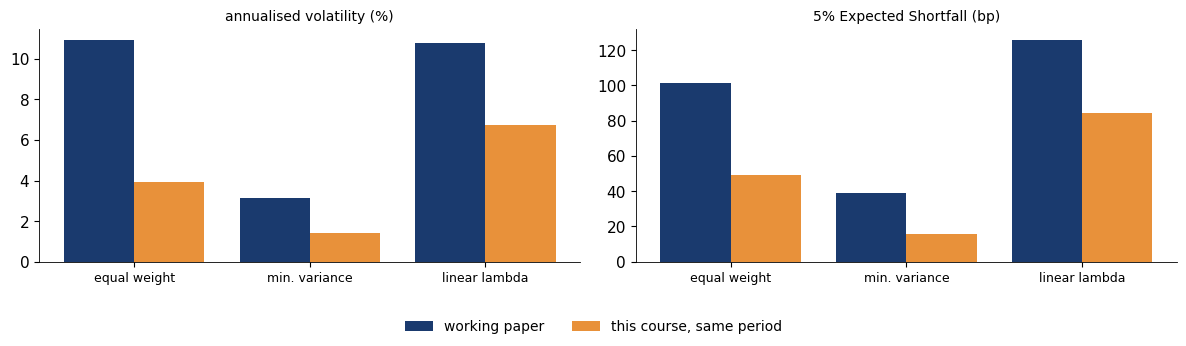

GMV against equal weight: volatility 63% lower, ES 67% lower (working paper: 71% and 62%)


In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
xx = np.arange(3)
for j_, (lab, col, pcol) in enumerate([('annualised volatility (%)', 'volatility (% a year)', 'working paper: volatility (%)'),
                                       ('5% Expected Shortfall (bp)', 'ES 5% (bp a day)', 'working paper: ES 5% (bp)')]):
    ax[j_].bar(xx - 0.2, PT[pcol].values, width=0.4, color=BLUE, label=('working paper' if j_ == 0 else None))
    ax[j_].bar(xx + 0.2, PT[col].values, width=0.4, color=BTC, label=('this course, same period' if j_ == 0 else None))
    ax[j_].set_xticks(xx); ax[j_].set_xticklabels(['equal weight', 'min. variance', 'linear lambda'], fontsize=9); ax[j_].set_title(lab, fontsize=10)
finish_fig(fig, 'ba_l6_portfolios', ncol=2, bottom=0.12)
ew_, gm_ = PT.loc['equal weight'], PT.loc['global minimum variance']
print(f'GMV against equal weight: volatility {100 * (1 - gm_.iloc[1] / ew_.iloc[1]):.0f}% lower, ES {100 * (1 - gm_.iloc[2] / ew_.iloc[2]):.0f}% lower (working paper: 71% and 62%)')

Covariance beats penalties: GMV cuts volatility and ES by about two thirds against equal weight, while penalty-based weights add risk and turnover.

### Value and drawdown, 2020–2026

We extend the three rules to 23 October 2026, after the end of the paper's sample, when sUSD collapsed. Left: the value of 1 USD invested on 30 June 2020 (reference-adjusted returns); right: the drawdown from the running peak.

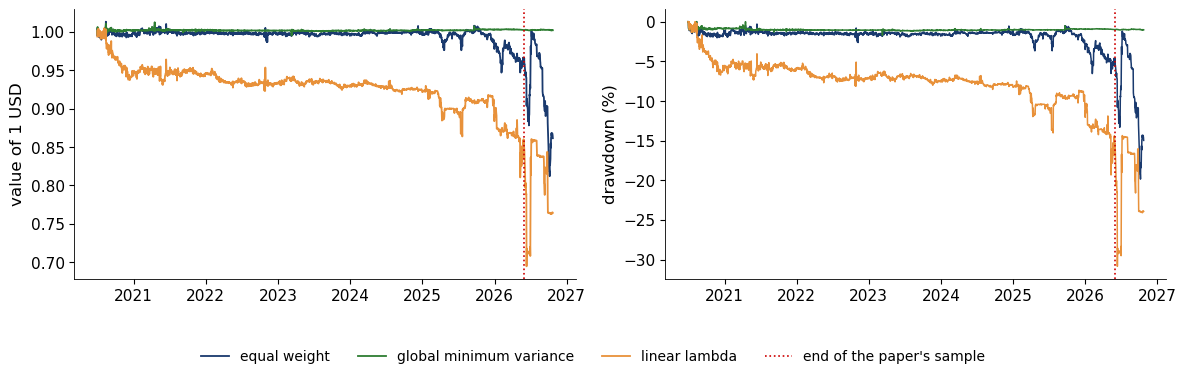

Portfolios, 30 Jun 2020 - 23 Oct 2026


,return (% a year),volatility (% a year),ES 5% (bp a day),max drawdown (%),turnover per rebalance (%)
equal weight,-2.20,5.74,70.47,19.85,0.37
global minimum variance,0.04,1.39,15.33,1.71,3.63
linear lambda,-3.68,10.62,111.40,30.85,57.30


In [32]:
PT2, W2, PR = run(END)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
pcols = {'equal weight': BLUE, 'global minimum variance': GREEN, 'linear lambda': BTC}
for k, col in pcols.items():
    nav = np.cumprod(1 + PR[k] / 1e4)
    ax[0].plot(nav.index, nav, color=col, lw=1.3, label=k)
    ax[1].plot(nav.index, 100 * (nav / nav.cummax() - 1), color=col, lw=1.1)
for a in ax:
    a.axvline(pd.Timestamp(END_PAPER), color=RED, ls=':', lw=1.2)
ax[0].plot([], [], color=RED, ls=':', lw=1.2, label="end of the paper's sample")
ax[0].set_ylabel('value of 1 USD'); ax[1].set_ylabel('drawdown (%)')
finish_fig(fig, 'ba_l6_nav', ncol=4, bottom=0.14)
print('Portfolios, 30 Jun 2020 - 23 Oct 2026')
PT2.round(2)

GMV stays within about 2% of its peak over six years. Equal weight triples its drawdown once sUSD collapses (from about 6.5% to about 19.9%), and linear lambda loses about 6% in its first months and more in each stress episode: risk without a reward.

### What the minimum-variance portfolio holds

Monthly averages of the GMV weights, June 2020 – May 2026:

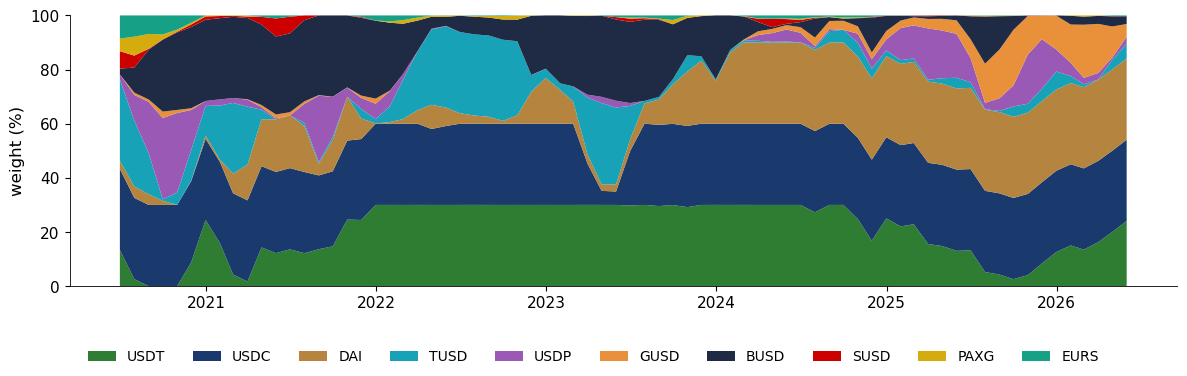

average GMV weights (%): {'USDC': 28.8, 'USDT': 21.1, 'DAI': 16.9, 'BUSD': 14.9, 'TUSD': 8.2, 'USDP': 5.2, 'GUSD': 3.1, 'EURS': 0.8, 'SUSD': 0.5, 'PAXG': 0.5}


In [33]:
gw = Wp['global minimum variance'].resample('ME').mean() * 100
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.stackplot(gw.index, [gw[c] for c in COINS], labels=COINS,
             colors=[GREEN, BLUE, GOLD, TEAL, ETH, BTC, NAVY, RED, '#D4AC0D', '#16A085'])
ax.set_ylabel('weight (%)'); ax.set_ylim(0, 100)
finish_fig(fig, 'ba_l6_gmv_weights', ncol=10, bottom=0.12)
print('average GMV weights (%):', (100 * Wp['global minimum variance'].mean()).round(1).sort_values(ascending=False).to_dict())

The 30% cap binds often: without it GMV would hold even more USDC and USDT, that is, more issuer concentration.

### Worked example: penalty coefficients as portfolio weights

$\hat\lambda_{j,t}$ is the regularisation chosen for one equation: it depends on how the *other* coins move in coin $j$'s lower tail, not on coin $j$'s own risk.
A small, erratic token (high variance, few co-movements) can get a *low* $\hat\lambda$ and then a 30% weight under the linear rule.
GMV, in contrast, reacts to the token's own variance. Before 12 June 2026, the 90-day standard deviation of daily returns was:

In [34]:
for c in ['SUSD', 'USDC']:
    print(f'{c}: 90-day sd of daily reference-adjusted returns before 12 June 2026 = {R[c].loc[:"2026-06-11"].iloc[-90:].std():.1f} bp')
print(f'GMV weight on sUSD on 11 June 2026: {100 * W2["global minimum variance"].loc["2026-06-11", "SUSD"]:.2f}%')
print(f'linear lambda: volatility {PT.loc["linear lambda", "volatility (% a year)"]:.1f}% a year vs {PT.loc["global minimum variance", "volatility (% a year)"]:.1f}% for GMV; '
      f'turnover {PT.loc["linear lambda", "turnover per rebalance (%)"]:.1f}% per week')

SUSD: 90-day sd of daily reference-adjusted returns before 12 June 2026 = 364.4 bp
USDC: 90-day sd of daily reference-adjusted returns before 12 June 2026 = 1.1 bp
GMV weight on sUSD on 11 June 2026: 0.04%
linear lambda: volatility 6.7% a year vs 1.4% for GMV; turnover 56.8% per week


The linear-lambda rule turns over more than half of the portfolio every week because the ranking of $\hat\lambda$ changes almost at every rebalancing, and it holds risky tokens whenever their tail links are weak.
GMV had already moved out of sUSD because its volatility had exploded, which is why it was protected when sUSD collapsed.